# Влияние длины контекста на обучение GPT

Сравнение символьной модели GPT из [репозитория А. Карпати](https://github.com/karpathy/ng-video-lecture) при `block_size=64` и `block_size=128` на наборе Tiny Shakespeare (`input.txt`).

Цель — сравнить ошибку на обучающей и валидационной выборках, время обучения и примеры сгенерированного текста.

In [ ]:
import ast
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | {torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'}")

In [ ]:
def load_karpathy_module():
    source = Path("gpt.py")
    tree = ast.parse(source.read_text(encoding="utf-8"), filename=str(source))
    cutoff = next(
        i for i, node in enumerate(tree.body)
        if isinstance(node, ast.Assign)
        and any(isinstance(t, ast.Name) and t.id == "model" for t in node.targets)
    )
    env = {"__name__": "karpathy_gpt", "__file__": str(source.resolve())}
    exec(compile(ast.Module(body=tree.body[:cutoff], type_ignores=[]), str(source), "exec"), env)
    return env

base_env = load_karpathy_module()
print(f"Словарь: {base_env['vocab_size']} символов")

In [ ]:
COMMON_CONFIG = {
    "batch_size": 16,
    "max_iters": 800,
    "eval_interval": 200,
    "eval_iters": 30,
    "learning_rate": 0.0003,
    "n_embd": 64,
    "n_head": 4,
    "n_layer": 2,
    "dropout": 0.1,
}
CONFIG_64 = dict(COMMON_CONFIG, block_size=64, label="context_64")
CONFIG_128 = dict(COMMON_CONFIG, block_size=128, label="context_128")


def saved_model_dir(parent, context_length):
    parent = Path(parent)
    current = parent / f"context_{context_length}"
    legacy = parent / ("baseline_64" if context_length == 64 else "variant8_128")
    return current if current.is_dir() or not legacy.is_dir() else legacy


def train_experiment(cfg, out_dir, seed=1337, verbose=True, save_weights=False):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    env = load_karpathy_module()
    env.update(cfg)
    env["device"] = device

    torch.manual_seed(seed)
    if device == "cuda":
        torch.cuda.manual_seed_all(seed)

    model = env["GPTLanguageModel"]().to(device)
    env["model"] = model
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["learning_rate"])
    history = []
    start_time = time.perf_counter()

    def evaluate(step):
        losses = env["estimate_loss"]()
        record = {
            "step": step,
            "train_loss": float(losses["train"]),
            "val_loss": float(losses["val"]),
        }
        history.append(record)
        if verbose and (step % max(cfg["eval_interval"], cfg["max_iters"] // 10) == 0 or step == cfg["max_iters"]):
            print(f"{cfg['label']} | seed {seed} | шаг {step}: train={record['train_loss']:.4f}, val={record['val_loss']:.4f}")
        return record

    for step in range(cfg["max_iters"]):
        if step % cfg["eval_interval"] == 0:
            evaluate(step)
        xb, yb = env["get_batch"]("train")
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    final = evaluate(cfg["max_iters"])
    training_seconds = round(time.perf_counter() - start_time, 2)

    if save_weights:
        torch.save(model.state_dict(), out_dir / "model.pt")

    model.eval()
    torch.manual_seed(2026)
    if device == "cuda":
        torch.cuda.manual_seed_all(2026)
    with torch.no_grad():
        context = torch.zeros((1, 1), dtype=torch.long, device=device)
        generated = model.generate(context, max_new_tokens=300)[0].tolist()
    generated_text = env["decode"](generated)

    summary = {
        "label": cfg["label"],
        "seed": seed,
        "block_size": cfg["block_size"],
        "parameters": cfg,
        "param_count": sum(p.numel() for p in model.parameters()),
        "final_train_loss": final["train_loss"],
        "final_val_loss": final["val_loss"],
        "training_seconds": training_seconds,
        "history": history,
        "generated_sample": generated_text[:120].strip(),
    }
    pd.DataFrame(history).to_csv(out_dir / "loss.csv", index=False)
    (out_dir / "generated.txt").write_text(generated_text, encoding="utf-8")
    (out_dir / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    return summary

## 1. Основной эксперимент

Две модели обучаются с нуля по 800 шагов при `seed=1337`.

In [19]:
LOAD_PRIMARY = None  # None — новый запуск; иначе имя сохранённой папки

if LOAD_PRIMARY is None:
    primary_dir = Path("results") / time.strftime("primary_run_%Y%m%d_%H%M%S")
    summary_64 = train_experiment(CONFIG_64, primary_dir / "context_64")
    summary_128 = train_experiment(CONFIG_128, primary_dir / "context_128")
else:
    primary_dir = Path("results") / LOAD_PRIMARY
    summary_64 = json.loads((saved_model_dir(primary_dir, 64) / "summary.json").read_text(encoding="utf-8"))
    summary_128 = json.loads((saved_model_dir(primary_dir, 128) / "summary.json").read_text(encoding="utf-8"))

context_64 | seed 1337 | шаг 200: train=2.6904, val=2.6917
context_64 | seed 1337 | шаг 400: train=2.5079, val=2.5041
context_64 | seed 1337 | шаг 600: train=2.4264, val=2.4269
context_64 | seed 1337 | шаг 800: train=2.3535, val=2.3508
context_128 | seed 1337 | шаг 0: train=4.1840, val=4.1877
context_128 | seed 1337 | шаг 200: train=2.6808, val=2.6832
context_128 | seed 1337 | шаг 400: train=2.5192, val=2.5062
context_128 | seed 1337 | шаг 600: train=2.4523, val=2.4528
context_128 | seed 1337 | шаг 800: train=2.3871, val=2.3914


,Контекст,Train Loss,Val Loss,"Время, с"
0,64,2.3535,2.3508,18.08
1,128,2.3871,2.3914,18.11


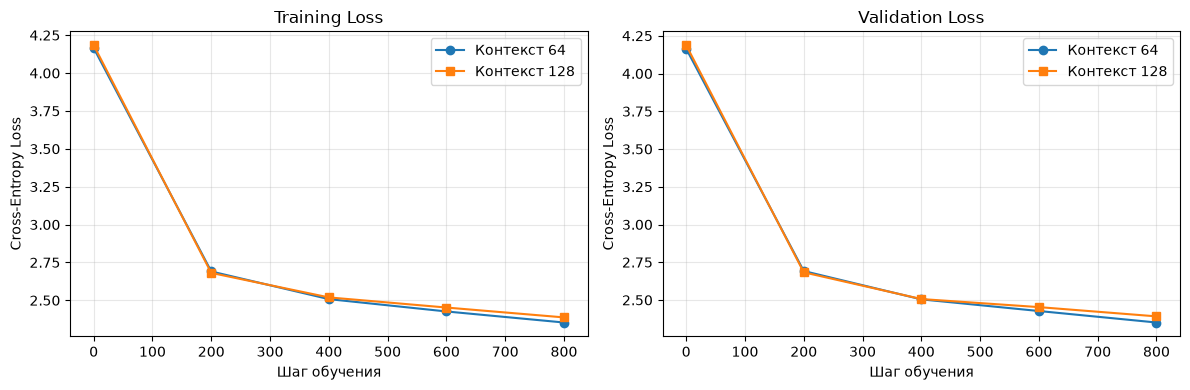

Контекст 64:

LEO:
Se wourshe pers bis. Whout bloove, awed, ddiregr los
ZLBurtptestacogwef foyongf p;
jeince burthhissk tes gerieme,
Gonm, wen y thisthe fare se toongneng,
An thery tesomy trp worep,
Act hanshes fr

Контекст 128:

LEO:
Se, nomber pers bis. ss,

O Go buryowedwidds cgral!

ZLBurthe stacogwef foyongf p; jeince bortherdsk tof gerilis,
Gonm, wen, d ul sthaker tse toongneng, w hiowencotharndtr toorer,
Act hanshes fr



In [20]:
primary_table = pd.DataFrame([
    {"Контекст": 64, "Train Loss": summary_64["final_train_loss"], "Val Loss": summary_64["final_val_loss"], "Время, с": summary_64["training_seconds"]},
    {"Контекст": 128, "Train Loss": summary_128["final_train_loss"], "Val Loss": summary_128["final_val_loss"], "Время, с": summary_128["training_seconds"]},
])
display(primary_table.round(4))

df_64 = pd.read_csv(saved_model_dir(primary_dir, 64) / "loss.csv")
df_128 = pd.read_csv(saved_model_dir(primary_dir, 128) / "loss.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ["train_loss", "val_loss"], ["Training Loss", "Validation Loss"]):
    ax.plot(df_64["step"], df_64[metric], marker="o", label="Контекст 64")
    ax.plot(df_128["step"], df_128[metric], marker="s", label="Контекст 128")
    ax.set(title=title, xlabel="Шаг обучения", ylabel="Cross-Entropy Loss")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

for size in (64, 128):
    print(f"Контекст {size}:\n" + (saved_model_dir(primary_dir, size) / "generated.txt").read_text(encoding="utf-8")[:200] + "\n")

In [21]:
delta = summary_128["final_val_loss"] - summary_64["final_val_loss"]
print(f"После 800 шагов: Val Loss(64) = {summary_64['final_val_loss']:.4f}; Val Loss(128) = {summary_128['final_val_loss']:.4f}.")
print(f"Разница (128 − 64): {delta:+.4f}. Меньшее значение Loss соответствует лучшему результату.")

После 800 шагов: Val Loss(64) = 2.3508; Val Loss(128) = 2.3914.
Разница (128 − 64): +0.0406. Меньшее значение Loss соответствует лучшему результату.


## 2. Проверка на 10 seed

Для каждого из десяти seed обе конфигурации обучались заново. Ниже представлены средние значения итогового Validation Loss и времени обучения.

In [22]:
SEEDS = [1337, 42, 101, 2024, 777, 999, 1234, 5555, 8888, 9999]
RUN_MULTISEED = False
LOAD_MULTISEED = None  # имя папки или None для последнего сохранённого запуска

multi_dir = None
if RUN_MULTISEED:
    multi_dir = Path("results") / time.strftime("multiseed_%Y%m%d_%H%M%S")
    records = []
    for seed in SEEDS:
        folder = multi_dir / f"seed_{seed}"
        a = train_experiment(CONFIG_64, folder / "context_64", seed=seed, verbose=False)
        b = train_experiment(CONFIG_128, folder / "context_128", seed=seed, verbose=False)
        records.append({
            "seed": seed,
            "val_loss_64": a["final_val_loss"],
            "val_loss_128": b["final_val_loss"],
            "diff_val": b["final_val_loss"] - a["final_val_loss"],
            "time_64": a["training_seconds"],
            "time_128": b["training_seconds"],
        })
        print(f"seed {seed}: {a['final_val_loss']:.4f} / {b['final_val_loss']:.4f}")
    pd.DataFrame(records).to_csv(multi_dir / "multiseed_summary.csv", index=False)
else:
    candidates = sorted(Path("results").glob("multiseed_*/multiseed_summary.csv"))
    if LOAD_MULTISEED:
        multi_dir = Path("results") / LOAD_MULTISEED
    elif candidates:
        multi_dir = candidates[-1].parent

multiseed_df = (
    pd.read_csv(multi_dir / "multiseed_summary.csv")
    if multi_dir is not None and (multi_dir / "multiseed_summary.csv").is_file()
    else pd.DataFrame()
)
if multi_dir:
    print(f"Результаты: {multi_dir}")

Результаты: results\multiseed_20261022_212526


In [23]:
if not multiseed_df.empty:
    means = pd.DataFrame([
        {"Контекст": 64, "Средний Val Loss": multiseed_df["val_loss_64"].mean(), "Среднее время, с": multiseed_df["time_64"].mean()},
        {"Контекст": 128, "Средний Val Loss": multiseed_df["val_loss_128"].mean(), "Среднее время, с": multiseed_df["time_128"].mean()},
    ])
    display(means.round(4))
    difference = (multiseed_df["val_loss_128"] - multiseed_df["val_loss_64"])
    print(f"Средняя разница (128 − 64): {difference.mean():+.4f}")
    print(f"Контекст 64 лучше в {(difference > 0).sum()} из {len(difference)} запусков.")
else:
    print("Нет сохранённых результатов. Для нового эксперимента задайте RUN_MULTISEED = True.")

,Контекст,Средний Val Loss,"Среднее время, с"
0,64,2.3413,17.619
1,128,2.3925,17.261


Средняя разница (128 − 64): +0.0512
Контекст 64 лучше в 10 из 10 запусков.


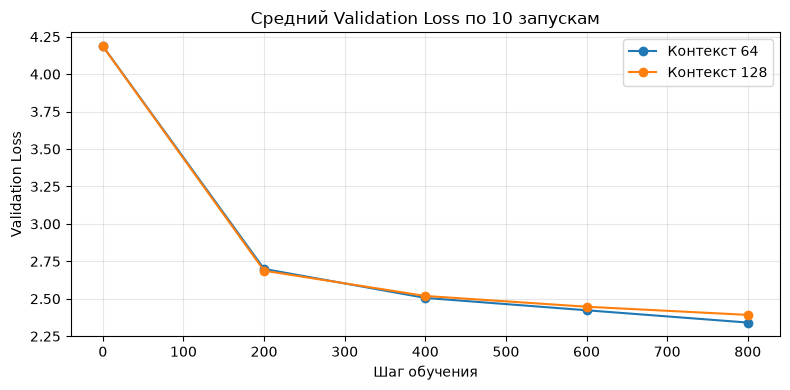

In [24]:
if not multiseed_df.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    for size in (64, 128):
        histories = []
        for seed in multiseed_df["seed"]:
            path = saved_model_dir(multi_dir / f"seed_{int(seed)}", size) / "loss.csv"
            if path.is_file():
                histories.append(pd.read_csv(path).set_index("step")["val_loss"])
        if histories:
            avg_loss = pd.concat(histories, axis=1).mean(axis=1)
            ax.plot(avg_loss.index, avg_loss.values, marker="o", label=f"Контекст {size}")
    ax.set(title="Средний Validation Loss по 10 запускам", xlabel="Шаг обучения", ylabel="Validation Loss")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

## 3. Дополнительный эксперимент — 30 000 шагов

Проверка влияния более длительного обучения на модели с контекстом 64 и 128. Результаты рассматриваются отдельно от основного эксперимента на 800 шагах.

context_64 | seed 1337 | шаг 0: train=4.1653, val=4.1645
context_64 | seed 1337 | шаг 3000: train=1.8055, val=1.9449
context_64 | seed 1337 | шаг 6000: train=1.6883, val=1.8547
context_64 | seed 1337 | шаг 9000: train=1.6312, val=1.8011
context_64 | seed 1337 | шаг 12000: train=1.5851, val=1.7823
context_64 | seed 1337 | шаг 15000: train=1.5587, val=1.7574
context_64 | seed 1337 | шаг 18000: train=1.5687, val=1.7587
context_64 | seed 1337 | шаг 21000: train=1.5315, val=1.7195
context_64 | seed 1337 | шаг 24000: train=1.5291, val=1.7132
context_64 | seed 1337 | шаг 27000: train=1.5098, val=1.7078
context_64 | seed 1337 | шаг 30000: train=1.4869, val=1.6754
context_128 | seed 1337 | шаг 0: train=4.1840, val=4.1877
context_128 | seed 1337 | шаг 3000: train=1.7806, val=1.9169
context_128 | seed 1337 | шаг 6000: train=1.6433, val=1.8212
context_128 | seed 1337 | шаг 9000: train=1.5720, val=1.7648
context_128 | seed 1337 | шаг 12000: train=1.5560, val=1.7266
context_128 | seed 1337 | шаг 150

,Контекст,Train Loss,Val Loss,"Время, с"
0,64,1.4869,1.6754,656.68
1,128,1.4905,1.6613,640.35


Контекст,64,128
Шагов,,
10000,1.7987,1.7641
30000,1.6754,1.6613


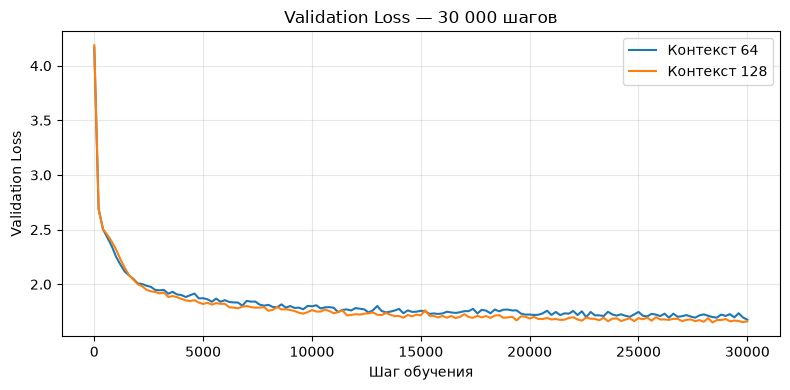

In [25]:
RUN_EXTENDED = True
CONFIG_EXT_64 = dict(CONFIG_64, max_iters=30_000)
CONFIG_EXT_128 = dict(CONFIG_128, max_iters=30_000)

if RUN_EXTENDED:
    ext_dir = Path("results") / time.strftime("extended_30000_%Y%m%d_%H%M%S")
    ext_64 = train_experiment(CONFIG_EXT_64, ext_dir / "context_64", seed=1337, save_weights=True)
    ext_128 = train_experiment(CONFIG_EXT_128, ext_dir / "context_128", seed=1337, save_weights=True)
    extended_table = pd.DataFrame([
        {"Контекст": 64, "Train Loss": ext_64["final_train_loss"], "Val Loss": ext_64["final_val_loss"], "Время, с": ext_64["training_seconds"]},
        {"Контекст": 128, "Train Loss": ext_128["final_train_loss"], "Val Loss": ext_128["final_val_loss"], "Время, с": ext_128["training_seconds"]},
    ])
    display(extended_table.round(4))
    older_runs = sorted(Path("results").glob("extended_10000_*"))
    if older_runs:
        comparison = []
        for steps, folder in [(10_000, older_runs[-1]), (30_000, ext_dir)]:
            for size in (64, 128):
                summary = json.loads((saved_model_dir(folder, size) / "summary.json").read_text(encoding="utf-8"))
                comparison.append({"Шагов": steps, "Контекст": size, "Val Loss": summary["final_val_loss"]})
        display(pd.DataFrame(comparison).pivot(index="Шагов", columns="Контекст", values="Val Loss").round(4))
    fig, ax = plt.subplots(figsize=(8, 4))
    for size in (64, 128):
        df = pd.read_csv(ext_dir / f"context_{size}" / "loss.csv")
        ax.plot(df["step"], df["val_loss"], label=f"Контекст {size}")
    ax.set(title="Validation Loss — 30 000 шагов", xlabel="Шаг обучения", ylabel="Validation Loss")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

## 4. Генерация текста

Для обеих моделей используется одинаковое начало текста. Каждый следующий символ выбирается из предсказанного моделью распределения вероятностей.

In [27]:
PROMPT = "ROMEO:\n"
NEW_TOKENS = 1000
GENERATION_SEED = 2026

runs = sorted(Path("results").glob("extended_30000_*"))
if not runs:
    print("Сначала выполните эксперимент на 30 000 шагов.")
else:
    run = runs[-1]
    for size in (64, 128):
        config = CONFIG_EXT_64 if size == 64 else CONFIG_EXT_128
        env = load_karpathy_module()
        env.update(config)
        env["device"] = device
        model = env["GPTLanguageModel"]().to(device)
        weights = run / f"context_{size}" / "model.pt"
        if not weights.exists():
            print(f"Контекст {size}: веса не найдены ({weights})")
            continue
        model.load_state_dict(torch.load(weights, map_location=device, weights_only=True))
        model.eval()

        torch.manual_seed(GENERATION_SEED)
        if device == "cuda":
            torch.cuda.manual_seed_all(GENERATION_SEED)
        context = torch.tensor([env["encode"](PROMPT)], dtype=torch.long, device=device)
        with torch.inference_mode():
            tokens = model.generate(context, max_new_tokens=NEW_TOKENS)[0].tolist()
        print(f"\nКонтекст {size}:\n{env['decode'](tokens)}\n")


Контекст 64:
ROMEO:
Let for yourself.

ROMEO:
What is movery wear dost grants: yet the slack.

ESTANGUE:
I'll, my lord. These to came, my in Grorden,
And heart all see to her be with thy beart,
trother patictors, and from the mastand!
Rich defore you from thou shalt wilt be all have him sundert,
But thy disporting here at it another,
To than would cour with is the cway tears:
Your can is, and court changs these chught?

ESCALUS:
Thou wilt do father, we does was it their that's they have
cose bearning the condone, prisolients, sir? tis my Romeo, gentlement witers.
Romeo speak speak:
Your cousin trus, my solaze doum'd and me,
Hare lead pulive a
warth age, gracious 'twoman leten him that bear sire
Report Tyblen cleave my away, if fre.

ROMEO:
Then, Come, forth, and queen, troty,
The father word your bring lipess
Much maten a rother Vips,-sir?

AUTOLYCUS:
Now, some, they priffere ofter, He have our beave absent?
I have hears dost war. This most and the bosom tread;
I have have haster here